# Bird species classification: autoencoder + MLP probe

1. Train a convolutional autoencoder on the 4800 unlabelled clips.
2. Use the encoder to turn each labelled clip into an embedding.
3. Train a small MLP classifier on those embeddings using the 200 labelled clips.
4. Predict the species of the 200 test clips.

In [37]:
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
from IPython.display import Audio, display
import torch
import torch.nn as nn
from pathlib import Path
from joblib import Parallel, delayed
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

ROOT = Path("/gws/ssde/j25b/iecdt/bio_practicals/bioacoustic")  # shared practical folder, so copies of this notebook work anywhere
DATA_DIR = ROOT / "data"
SR = 32000
N_MELS = 64
N_FRAMES = 312

torch.manual_seed(0)
np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

## Loading the data

Each clip is turned into a log-mel spectrogram of shape (64 mel bands × 312 time frames), scaled to lie between 0 and 1. (mel band is effectively logarithmic frequency band - meant to mimic human hearing)

In [38]:
def load_mel(path):
    y, _ = librosa.load(path, sr=SR, duration=5.0)
    y = librosa.util.fix_length(y, size=5 * SR)  # zero-pad clips shorter than 5 s
    mel = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=1024, hop_length=512, n_mels=N_MELS, fmin=50, fmax=14000)
    mel = librosa.power_to_db(mel, ref=np.max, top_db=80)
    return (mel[:, :N_FRAMES] / 80 + 1).astype(np.float32) #drop last time frame (312 is nice divisible number), divide by top_dB, scale [0,1]


def load_files(paths):
    return np.stack(Parallel(n_jobs=8)(delayed(load_mel)(p) for p in paths))

Computing spectrograms for 4800 clips takes a few mins, so we save them to `cache/` the first time.

In [39]:
unlab_paths = sorted((DATA_DIR / "unlabelled").glob("*.wav"))
cache = ROOT / "cache" / "unlabelled.npy"
if cache.exists():
    X_unlab = np.load(cache)
else:
    X_unlab = load_files(unlab_paths)
    cache.parent.mkdir(exist_ok=True)
    np.save(cache, X_unlab)

X_unlab.shape

(4800, 64, 312)

In [40]:
labels = pd.read_csv(DATA_DIR / "labelled" / "labels.csv")
classes, y_lab = np.unique(labels.species, return_inverse=True)  # sorted species names, integer label per clip
X_lab = load_files([DATA_DIR / "labelled" / f for f in labels.filename])

print(X_lab.shape)
labels.species.value_counts()

(200, 64, 312)


species
Eurasian Wren     90
Nothing heard     51
Song Thrush       31
European Robin    28
Name: count, dtype: int64

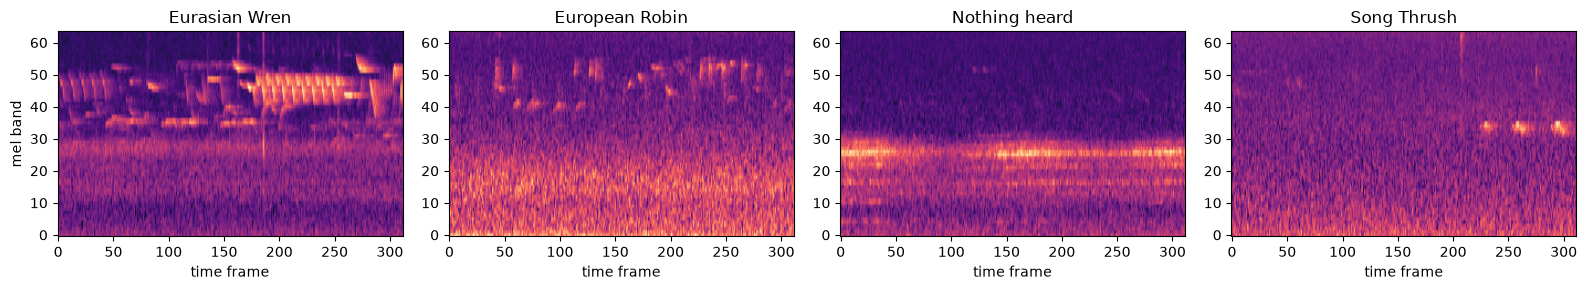

In [41]:
fig, axes = plt.subplots(1, len(classes), figsize=(4 * len(classes), 3))
for c, ax in enumerate(axes):
    ax.imshow(X_lab[y_lab == c][0], origin="lower", aspect="auto", cmap="magma")
    ax.set_title(classes[c])
    ax.set_xlabel("time frame")
axes[0].set_ylabel("mel band")
plt.tight_layout()

## Autoencoder

The encoder squeezes each 64 × 312 spectrogram down to a 128-dimensional embedding, and the decoder tries to rebuild the spectrogram from it.

In [42]:
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, 3, stride=2, padding=1), nn.ReLU(),   # 16 x 32 x 156
            nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.ReLU(),  # 32 x 16 x 78
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.ReLU(),  # 64 x 8 x 39
            nn.Flatten(),
            nn.Linear(64 * 8 * 39, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64 * 8 * 39), nn.ReLU(),
            nn.Unflatten(1, (64, 8, 39)),
            nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),
            nn.ConvTranspose2d(32, 16, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),
            nn.ConvTranspose2d(16, 1, 3, stride=2, padding=1, output_padding=1), nn.Sigmoid(),
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))


ae = Autoencoder().to(device)
sum(p.numel() for p in ae.parameters())

5178433

In [43]:
unlab_loader = DataLoader(TensorDataset(torch.tensor(X_unlab).unsqueeze(1)), batch_size=64, shuffle=True)

optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()
n_epochs = 20

ae_losses = []
for epoch in range(n_epochs):
    ae.train()
    total = 0
    for (xb,) in unlab_loader:
        xb = xb.to(device)
        loss = loss_fn(ae(xb), xb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item() * len(xb)
    ae_losses.append(total / len(unlab_loader.dataset))
    print(f"epoch {epoch + 1}: reconstruction loss {ae_losses[-1]:.4f}")

epoch 1: reconstruction loss 0.0115
epoch 2: reconstruction loss 0.0039
epoch 3: reconstruction loss 0.0032
epoch 4: reconstruction loss 0.0025
epoch 5: reconstruction loss 0.0024
epoch 6: reconstruction loss 0.0023
epoch 7: reconstruction loss 0.0022
epoch 8: reconstruction loss 0.0021
epoch 9: reconstruction loss 0.0021
epoch 10: reconstruction loss 0.0021
epoch 11: reconstruction loss 0.0020
epoch 12: reconstruction loss 0.0020
epoch 13: reconstruction loss 0.0020
epoch 14: reconstruction loss 0.0020
epoch 15: reconstruction loss 0.0019
epoch 16: reconstruction loss 0.0019
epoch 17: reconstruction loss 0.0019
epoch 18: reconstruction loss 0.0019
epoch 19: reconstruction loss 0.0018
epoch 20: reconstruction loss 0.0018


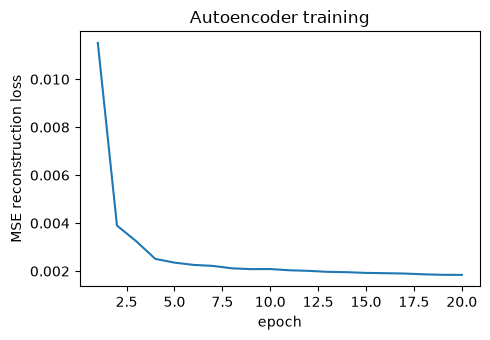

In [44]:
plt.figure(figsize=(5, 3.5))
plt.plot(range(1, n_epochs + 1), ae_losses)
plt.xlabel("epoch")
plt.ylabel("MSE reconstruction loss")
plt.title("Autoencoder training")
plt.tight_layout()

### Reconstructions

Five random unlabelled clips (top) and what the autoencoder rebuilds from their embeddings (bottom).

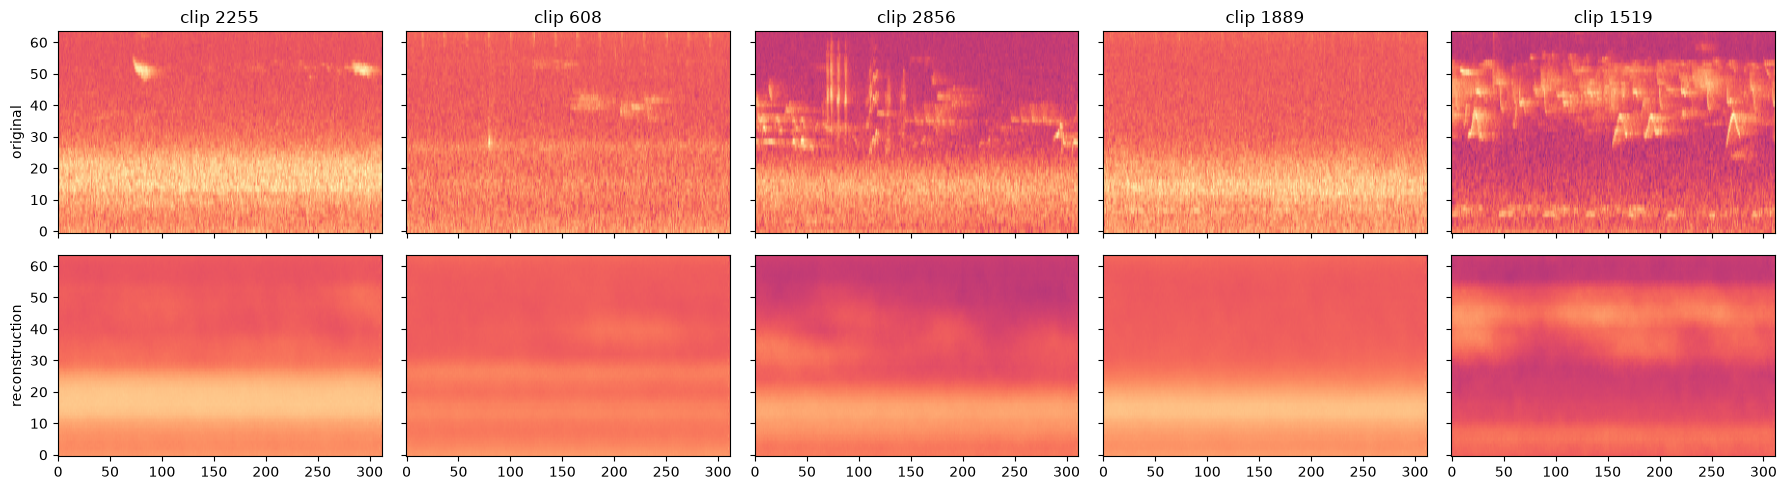

In [45]:
idx = np.random.choice(len(X_unlab), 5, replace=False)
ae.eval()
with torch.no_grad():
    recon = ae(torch.tensor(X_unlab[idx]).unsqueeze(1).to(device)).squeeze(1).cpu().numpy()

fig, axes = plt.subplots(2, 5, figsize=(18, 5), sharex=True, sharey=True)
for j, i in enumerate(idx):
    axes[0, j].imshow(X_unlab[i], origin="lower", aspect="auto", cmap="magma", vmin=0, vmax=1)
    axes[1, j].imshow(recon[j], origin="lower", aspect="auto", cmap="magma", vmin=0, vmax=1)
    axes[0, j].set_title(f"clip {i}")
axes[0, 0].set_ylabel("original")
axes[1, 0].set_ylabel("reconstruction")
plt.tight_layout()

## MLP probe

Freeze the encoder, embed the labelled clips, and train a small MLP (one hidden layer) on top.

In [47]:
def embed(X):
    ae.eval()
    with torch.no_grad():
        return ae.encoder(torch.tensor(X).unsqueeze(1).to(device)).cpu().numpy()


Z_lab = embed(X_lab)
Z_lab.shape

(200, 128)

In [48]:
Z_train, Z_val, y_train, y_val = train_test_split(Z_lab, y_lab, test_size=0.2, stratify=y_lab, random_state=0)
len(Z_train), len(Z_val)

(160, 40)

In [49]:
mean, std = Z_train.mean(0), Z_train.std(0) + 1e-6
Z_train_t = torch.tensor((Z_train - mean) / std).to(device)
Z_val_t = torch.tensor((Z_val - mean) / std).to(device)
y_train_t = torch.tensor(y_train).to(device)
y_val_t = torch.tensor(y_val).to(device)

In [50]:
probe = nn.Sequential(
    nn.Linear(Z_train_t.shape[1], 64), nn.ReLU(),  # hidden layer: 128 -> 64
    nn.Linear(64, len(classes)),                   # 64 -> class logits
).to(device)
optimizer = torch.optim.Adam(probe.parameters(), lr=1e-3, weight_decay=1e-3)
loss_fn = nn.CrossEntropyLoss()
n_epochs = 300

train_losses, val_losses, val_accs = [], [], []
for epoch in range(n_epochs):
    loss = loss_fn(probe(Z_train_t), y_train_t)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    train_losses.append(loss.item())

    with torch.no_grad():
        logits = probe(Z_val_t)
        val_losses.append(loss_fn(logits, y_val_t).item())
        val_accs.append((logits.argmax(1) == y_val_t).float().mean().item())

print(f"final val accuracy: {val_accs[-1]:.2f}")

final val accuracy: 0.70


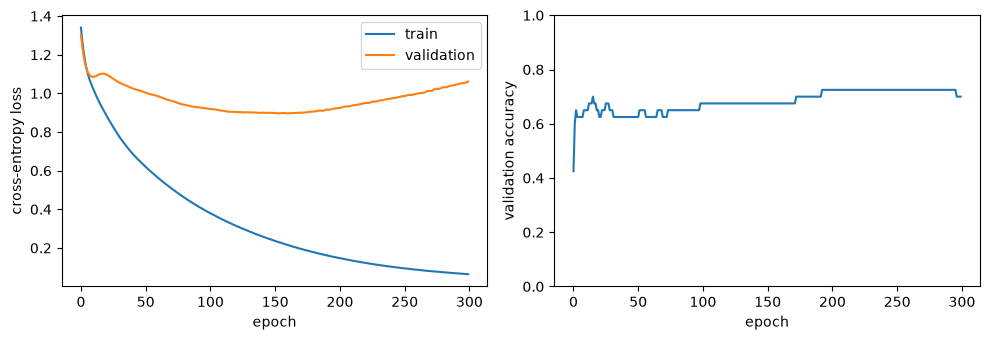

In [51]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.plot(train_losses, label="train")
ax1.plot(val_losses, label="validation")
ax1.set_xlabel("epoch")
ax1.set_ylabel("cross-entropy loss")
ax1.legend()
ax2.plot(val_accs)
ax2.set_xlabel("epoch")
ax2.set_ylabel("validation accuracy")
ax2.set_ylim(0, 1)
plt.tight_layout()

## Predicting on the test set

Run your model on the 200 unlabelled test clips. Put your group name in the cell below before saving — the cell will not run without it.

In [52]:
test_paths = sorted((DATA_DIR / "test").glob("*.wav"))
test_files = [p.name for p in test_paths]
X_test = load_files(test_paths)
X_test.shape

(200, 64, 312)

In [53]:
Z_test = torch.tensor((embed(X_test) - mean) / std).to(device)
with torch.no_grad():
    test_preds = probe(Z_test).argmax(1).cpu().numpy()

pd.Series([classes[i] for i in test_preds]).value_counts()

Nothing heard     78
Eurasian Wren     57
Song Thrush       36
European Robin    29
Name: count, dtype: int64

In [54]:
GROUP_NAME = 'tested'

group = GROUP_NAME.strip()
out_path = ROOT / "test_results" / f"{group.replace(' ', '_')}_autoencoder.csv"
out_path.parent.mkdir(exist_ok=True)

results = pd.DataFrame({
    "filename": test_files,
    "species": [classes[i] for i in test_preds],
    "model": "autoencoder",
    "group": group,
})
results.to_csv(out_path, index=False)
print(f"Saved {len(results)} predictions to {out_path}")
results.head()

Saved 200 predictions to /gws/ssde/j25b/iecdt/bio_practicals/bioacoustic/test_results/tested_autoencoder.csv


,filename,species,model,group
0,A4_20250306_175100_c2.wav,Nothing heard,autoencoder,tested
1,A5-2_20250717_050800_c8.wav,European Robin,autoencoder,tested
2,A5_20250511_032600_c1.wav,Song Thrush,autoencoder,tested
3,B2-2_20250907_193700_c4.wav,Nothing heard,autoencoder,tested
4,B2_20250419_063900_c0.wav,Song Thrush,autoencoder,tested
